# Random forests: classification and regression

**Part 1: Classification.** Predict diabetes (Pima dataset) from glucose, insulin, age and BMI.
- Random forest (100 trees, stratified 80/20 split): **73.4% test accuracy**
- Confusion matrix and feature importance: **glucose** (0.40) and **BMI** (0.27) are the strongest predictors.

**Part 2: Regression on building energy efficiency.** Predict the **heating load** of buildings from their
geometry (relative compactness, surface, wall and roof area, height, orientation, glazing area). Data: UCI Energy Efficiency dataset (ENB2012, 768 buildings).
- Random forest regressor with out-of-bag scoring, predicted-vs-actual plot, feature importance.

> **Review note (added later):** in this class version the feature set still contains the targets `Y1` (heating load) and `Y2` (cooling load), which is *target leakage* and explains the near-perfect R² of 0.999. The correct setup uses only the building features:
> `X = stock[['X1','X2','X3','X4','X5','X6','X7','X8']]`, `Y = stock['Y1']`.
> Spotting and fixing leakage like this is an important part of validating any model.

---
*Coursework: M.Eng. Engineering & Sustainable Technology Management, AI / Machine Learning courses (2025–2026). Originally run in Google Colab.*

# **RANDOM FOREST CLASIFFIER**

In [ ]:
from sklearn import datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score # this indicator for validity of model is applied for regressors
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree

In [ ]:
data = pd.read_csv('/content/diabetes.csv')
data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
762,9,89,62,0,0,22.5,0.142,33,0
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0


In [ ]:
x = data [['Glucose','Insulin','Age','BMI']]
y = data['Outcome']

In [ ]:
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
762,0
763,0
764,0
765,0


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(x,y,random_state=42, test_size=0.2, stratify=y)

In [ ]:
rfc = RandomForestClassifier(n_estimators=100, max_samples=0.5, random_state=42,oob_score=True)

In [ ]:
rfc.fit(X_train, Y_train)

RandomForestClassifier(max_samples=0.5, oob_score=True, random_state=42)

In [ ]:
y_pred = rfc.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score
y_pred = rfc.predict(X_test)
accuracy_score(Y_test, y_pred)

0.7337662337662337

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(Y_test, y_pred)
print(cm)


[[84 16]
 [25 29]]


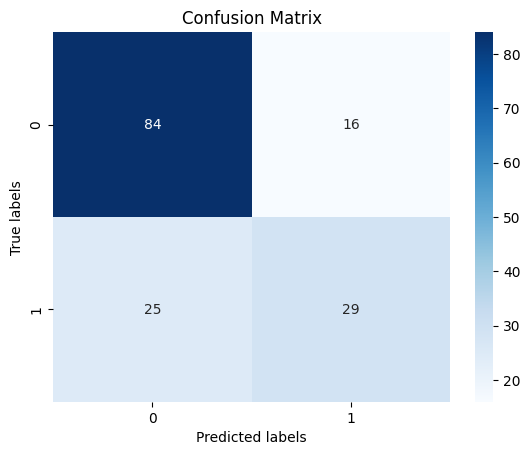

In [ ]:
sns.heatmap(cm, annot=True, cmap='Blues') # we use usually heatmap for visualisation of confusion matrix
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
importances = rfc.feature_importances_
importances

array([0.40339591, 0.12008254, 0.20207901, 0.27444254])

In [ ]:
indices = np.argsort(importances)[::-1]
indices

array([0, 3, 2, 1])

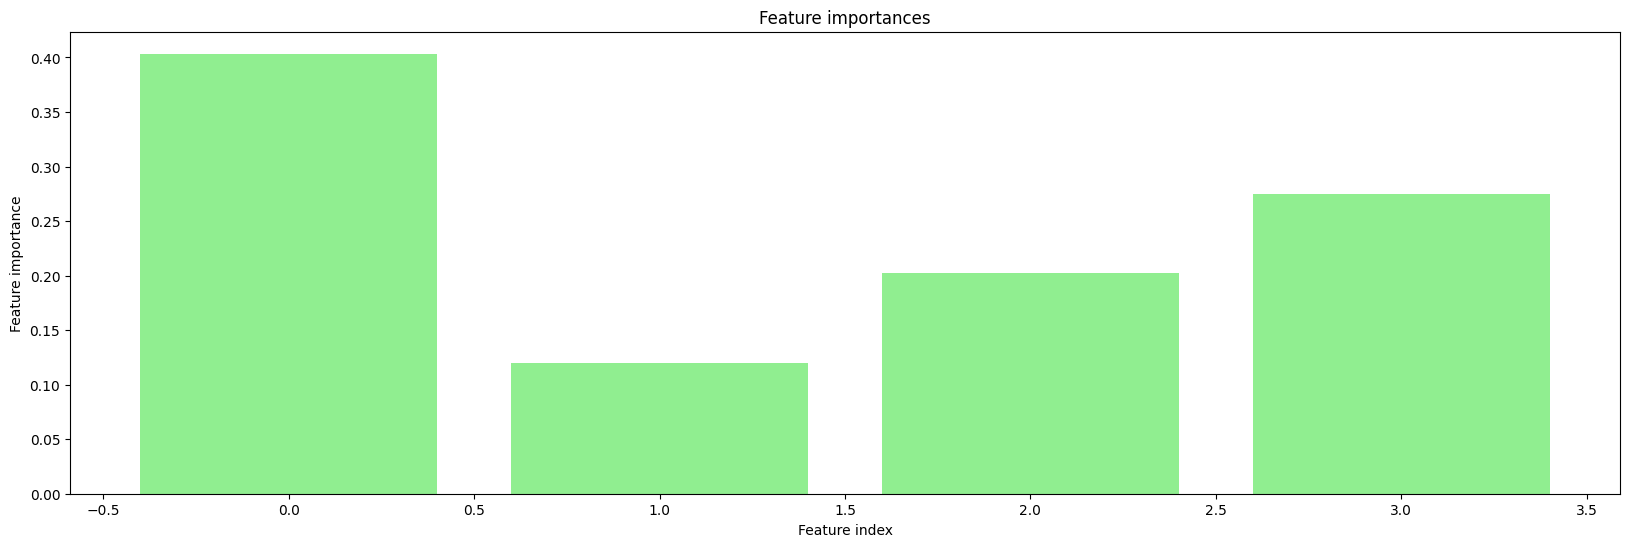

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 6))
plt.title("Feature importances")
plt.bar(indices, importances[indices],color='lightgreen')

plt.xlabel("Feature index")
plt.ylabel("Feature importance")
plt.show()

In [ ]:
importances[indices]

array([0.40339591, 0.27444254, 0.20207901, 0.12008254])

# **RANDOM FOREST REGRESSION**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score # this indicator for validity of model is applied for regressors
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree

In [ ]:
stock = pd.read_csv('/content/ENB2012_data.csv')

In [ ]:
stock

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28
...,...,...,...,...,...,...,...,...,...,...
763,0.64,784.0,343.0,220.50,3.5,5,0.4,5,17.88,21.40
764,0.62,808.5,367.5,220.50,3.5,2,0.4,5,16.54,16.88
765,0.62,808.5,367.5,220.50,3.5,3,0.4,5,16.44,17.11
766,0.62,808.5,367.5,220.50,3.5,4,0.4,5,16.48,16.61


In [ ]:
X = stock.loc[:, stock.columns != 'X5']
Y = stock['Y1']

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,random_state=42, test_size=0.2)

In [ ]:
print("Length Of training data ", len(X_train))
print("Length Of test data ", len(X_test))
print("Length Of training Y ", len(Y_train))
print("Length Of test data Y", len(Y_test))

Length Of training data  614
Length Of test data  154
Length Of training Y  614
Length Of test data Y 154


In [ ]:
stock.columns

Index(['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1', 'Y2'], dtype='object')

In [ ]:
stock.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
rfr = RandomForestRegressor(n_estimators=150, max_samples=0.6, random_state=42,oob_score=True,max_features='sqrt')

In [ ]:
rfr.fit(X_train, Y_train)

RandomForestRegressor(max_features='sqrt', max_samples=0.6, n_estimators=150,
                      oob_score=True, random_state=42)

In [ ]:
rfr.oob_score_

0.9987658284231575

In [ ]:
1 - rfr.oob_score_ # Errors of OOB

0.0012341715768424688

In [ ]:
y_rfr_pred = rfr.predict(X_test) # prediction based on the test sample (20% of whole data)

In [ ]:
print("Train r2 score", r2_score(Y_train, rfr.predict(X_train)))

Train r2 score 0.9996134581926988


In [ ]:
print("Test r2 score", r2_score(Y_test, y_rfr_pred)) # this it the accurecy score of the whole random forrest ,

Test r2 score 0.998997135796177


In [ ]:
y_rfr_pred

array([16.48293333, 13.27353333, 32.75506667, 41.26026667, 16.784     ,
       23.87      , 24.34773333, 28.6404    , 19.229     , 28.61506667,
       18.68246667, 33.0138    , 29.32726667, 10.36293333, 17.8816    ,
       36.75446667, 36.54793333, 12.25106667, 14.5798    , 32.51953333,
       28.7438    , 41.40206667, 11.579     , 36.596     , 15.31433333,
       36.18033333, 35.94866667, 28.9172    , 17.51346667, 13.8826    ,
       10.4122    , 12.32486667, 16.9008    , 26.89586667, 36.11373333,
       28.26853333, 32.65206667, 36.57726667, 35.59446667, 10.69526667,
       28.28566667, 12.2584    ,  6.31973333, 31.9562    ,  6.86446667,
        6.439     ,  7.13826667, 10.7576    , 28.8924    , 32.63586667,
       35.0246    , 12.902     , 12.95726667, 39.83306667, 12.27406667,
       15.3218    , 12.3584    , 25.43273333, 40.21613333, 36.0322    ,
       14.29586667, 16.45286667, 12.9244    , 23.56406667, 28.57413333,
       36.77466667, 35.96246667, 11.58793333, 12.97506667, 11.80

In [ ]:
y_rfr_pred.shape

(154,)

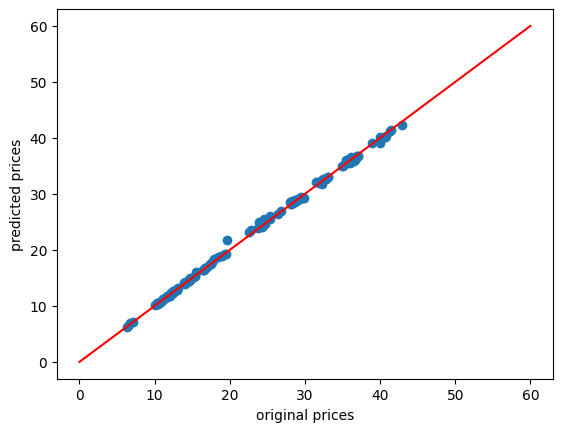

In [ ]:
plt.scatter(Y_test,y_rfr_pred )
plt.plot([0,10,20,60],[0,10,20,60],c='red')
plt.xlabel('original prices')
plt.ylabel('predicted prices')
plt.show()

In [ ]:
importances = rfr.feature_importances_ # this code gives you the importance of each variable to prediction of the close price

In [ ]:
importances

array([0.09677623, 0.13643698, 0.0121883 , 0.10073013, 0.00042147,
       0.01627104, 0.00605812, 0.39312814, 0.2379896 ])

In [ ]:
import numpy as np
indices = np.argsort(importances)

indices# order and location of number in acsending order

array([4, 6, 2, 5, 0, 3, 1, 8, 7])

In [ ]:
indices = np.argsort(importances)[::-1] # returns the indices that would sort the importances array in descending order [from high to low value]
indices

array([7, 8, 1, 3, 0, 5, 2, 6, 4])

In [ ]:
features = X_train.columns
features

Index(['X1', 'X2', 'X3', 'X4', 'X6', 'X7', 'X8', 'Y1', 'Y2'], dtype='object')

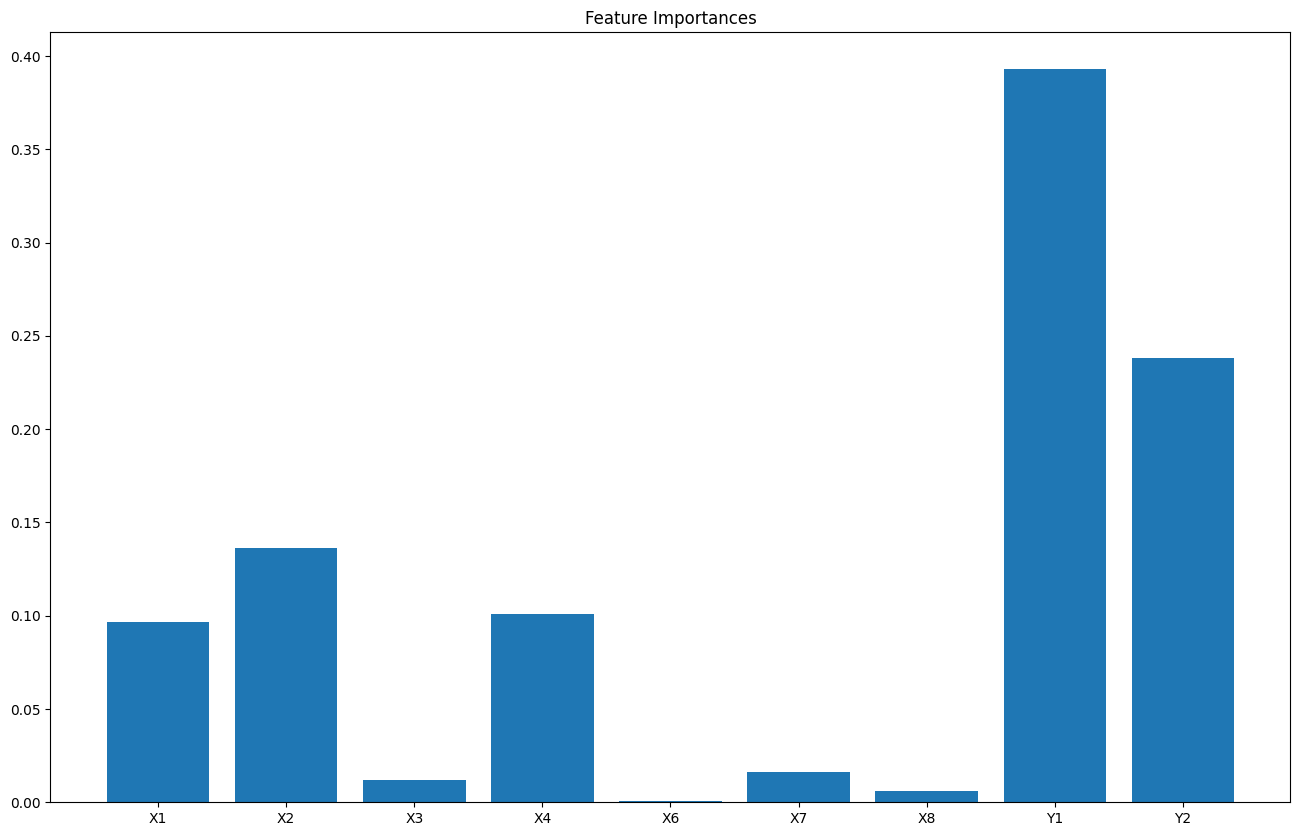

In [ ]:
plt.figure(figsize=(16,10))
plt.bar(features,importances)
plt.title('Feature Importances')
plt.show()

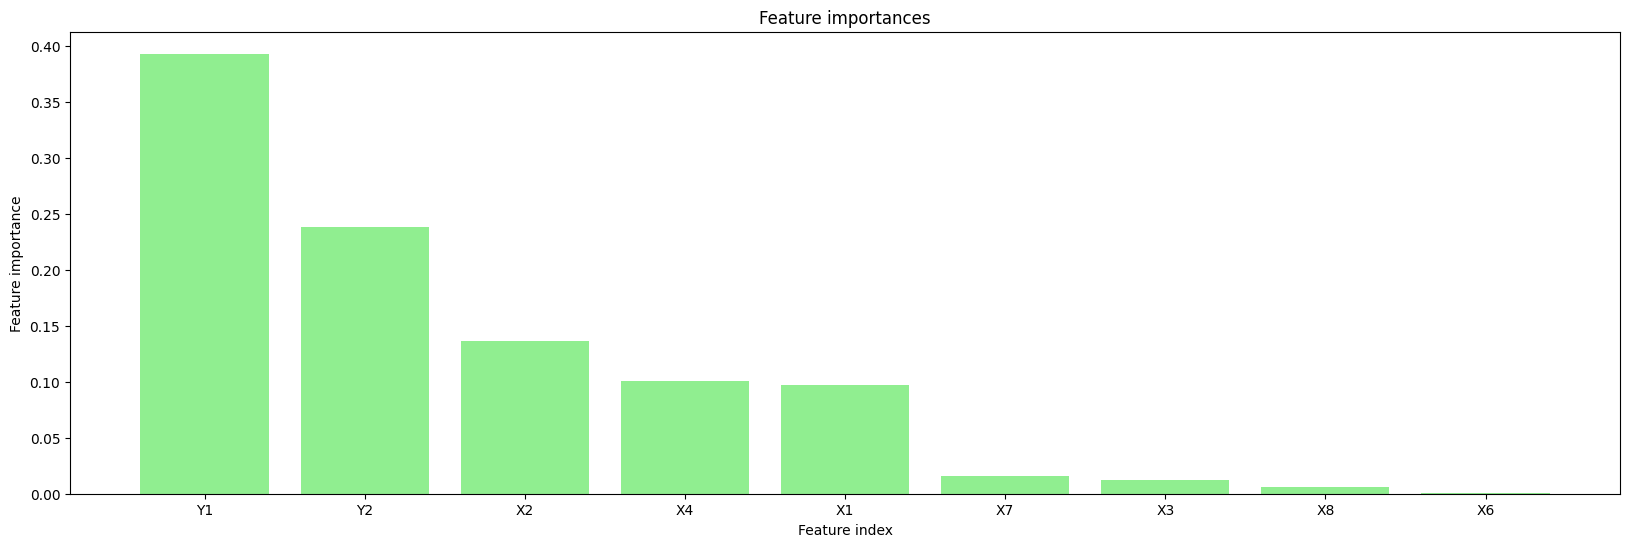

In [ ]:
# Plot the feature importances
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 6))
plt.title("Feature importances")
plt.bar(X.columns[indices], importances[indices],color='lightgreen')

plt.xlabel("Feature index")
plt.ylabel("Feature importance")
plt.show()

In [ ]:
importances

array([0.09677623, 0.13643698, 0.0121883 , 0.10073013, 0.00042147,
       0.01627104, 0.00605812, 0.39312814, 0.2379896 ])

In [ ]:
importances[indices]

array([0.39312814, 0.2379896 , 0.13643698, 0.10073013, 0.09677623,
       0.01627104, 0.0121883 , 0.00605812, 0.00042147])

In [ ]:
features = X_train.columns
features

Index(['X1', 'X2', 'X3', 'X4', 'X6', 'X7', 'X8', 'Y1', 'Y2'], dtype='object')

<function matplotlib.pyplot.show(close=None, block=None)>

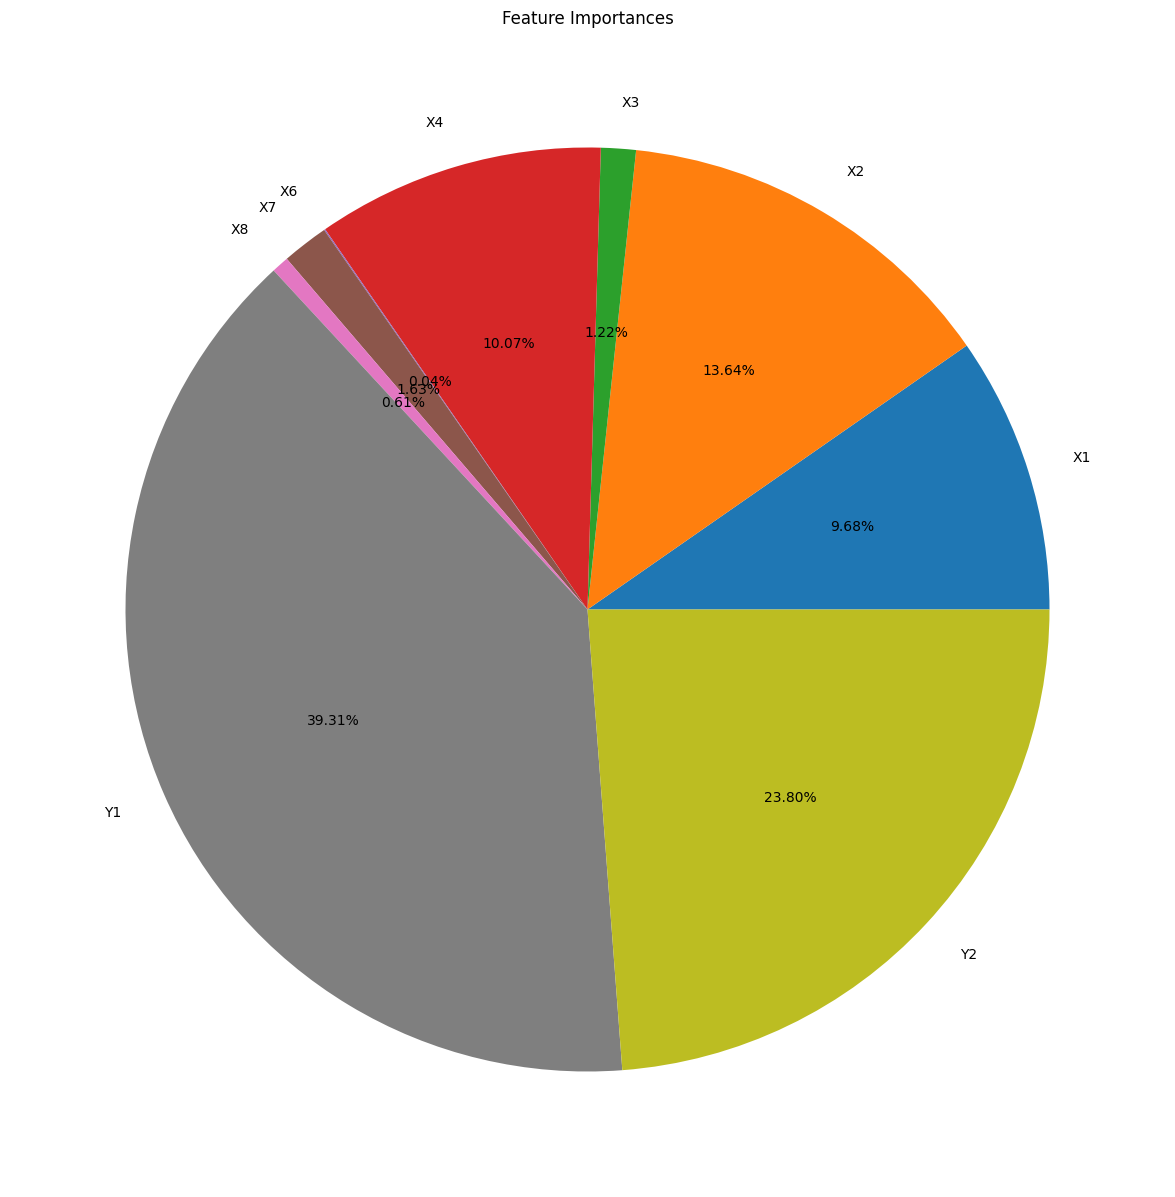

In [ ]:
plt.figure(figsize=(16,15))

plt.title('Feature Importances')

plt.pie(importances,labels=features,autopct='%2.2f%%')
plt.show

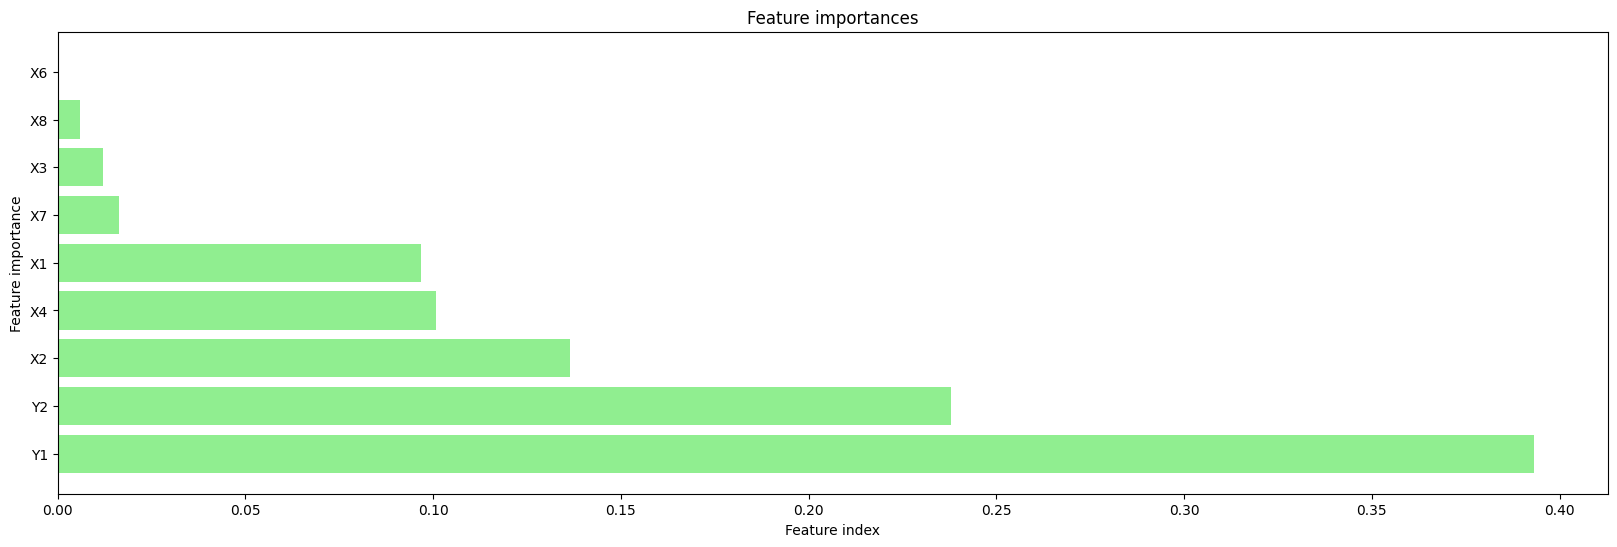

In [ ]:
# Plot the feature importances
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 6))
plt.title("Feature importances")
plt.barh(X.columns[indices], importances[indices],color='lightgreen')
#plt.xticks(range(x.shape[1]), indices)
plt.xlabel("Feature index")
plt.ylabel("Feature importance")
plt.show()